In [1]:
!gdown https://drive.google.com/uc?id=1xygcGyFTUOlgMQISojEk198mCWzvb8WP
!gdown https://drive.google.com/uc?id=1rKhQkwvwCLTRreVR7_gyEsF_WJEiIVqB
!unzip TestData.zip
!unzip TrainData.zip

A streamkimeneten csak az utolsó 5000 sor látható.
  inflating: TrainData/Sample057/img057-00156.png  
  inflating: TrainData/Sample057/img057-00157.png  
  inflating: TrainData/Sample057/img057-00158.png  
  inflating: TrainData/Sample057/img057-00159.png  
  inflating: TrainData/Sample057/img057-00160.png  
  inflating: TrainData/Sample057/img057-00161.png  
  inflating: TrainData/Sample057/img057-00162.png  
  inflating: TrainData/Sample057/img057-00163.png  
  inflating: TrainData/Sample057/img057-00164.png  
  inflating: TrainData/Sample057/img057-00165.png  
  inflating: TrainData/Sample057/img057-00166.png  
  inflating: TrainData/Sample057/img057-00167.png  
  inflating: TrainData/Sample057/img057-00168.png  
  inflating: TrainData/Sample057/img057-00169.png  
  inflating: TrainData/Sample057/img057-00170.png  
  inflating: TrainData/Sample057/img057-00171.png  
  inflating: TrainData/Sample057/img057-00172.png  
  inflating: TrainData/Sample057/img057-00173.png  
  inflating: 

In [2]:
import tensorflow as tf
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# --- Configuration ---
data_dir = "TrainData"
img_size = 128
batch_size = 32
seed = 192837465
max_epochs = 50

num_classes = 62
characters = list('0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz')
label_to_char_map = {i: char for i, char in enumerate(characters)}

In [3]:
train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    color_mode='grayscale',
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='int'
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    color_mode='grayscale',
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='int'
)

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Found 53172 files belonging to 62 classes.
Using 42538 files for training.
Found 53172 files belonging to 62 classes.
Using 10634 files for validation.


In [4]:
# Function to compute bounding box coordinates
def get_bounding_box(image, threshold=0.1):
    """
    Returns (y_min, x_min, y_max, x_max) for the non-background pixels
    """
    img = image.numpy().squeeze()  # shape (H,W)
    foreground = np.where(img > threshold)
    if len(foreground[0]) == 0:
        return 0, 0, img.shape[0], img.shape[1]
    y_min, y_max = foreground[0].min(), foreground[0].max()
    x_min, x_max = foreground[1].min(), foreground[1].max()
    return y_min, x_min, y_max, x_max

In [5]:
inputs = keras.Input(shape=(img_size, img_size, 1))

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
])
# Apply augmentation only during training
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)

# Helper function to create a Conv Block with BatchNormalization
def conv_block(x, filters):
    x = layers.Conv2D(filters, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    return x

# Deeper Architecture
x = conv_block(x, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = conv_block(x, 256)

x = layers.Flatten()(x)

# Dense Block
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,600,542 (17.55 MB)

 Trainable params: 4,599,070 (17.54 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [6]:
callbacks = [
    # Stop training if val_loss doesn't improve for x epochs
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    # Always save the best model based on validation accuracy
    keras.callbacks.ModelCheckpoint(
        filepath='best_character_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=max_epochs,
    callbacks=callbacks
)

Epoch 1/50
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4249 - loss: 2.2343
Epoch 1: val_accuracy improved from -inf to 0.73538, saving model to best_character_model.keras
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 76s 51ms/step - accuracy: 0.4251 - loss: 2.2338 - val_accuracy: 0.7354 - val_loss: 0.8161
Epoch 2/50
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7523 - loss: 0.7682
Epoch 2: val_accuracy improved from 0.73538 to 0.83487, saving model to best_character_model.keras
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 64s 48ms/step - accuracy: 0.7523 - loss: 0.7682 - val_accuracy: 0.8349 - val_loss: 0.4804
Epoch 3/50
1329/1330 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7850 - loss: 0.6204
Epoch 3: val_accuracy improved from 0.83487 to 0.84164, saving model to best_character_model.keras
1330/1330 ━━━━━━━━━━━━━━━━━━━━ 63s 47ms/step - accuracy: 0.7850 - loss: 0.6204 - val_accuracy: 0.8416 - val_loss: 0.4499
Epoch 4/50
1329/1330 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8064 - 

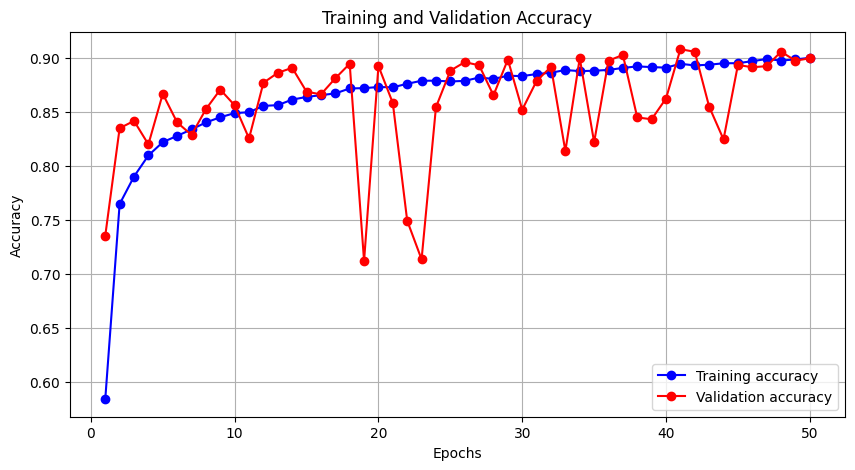

In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs_list = range(1, len(acc) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, acc, 'bo-', label='Training accuracy')
plt.plot(epochs_list, val_acc, 'ro-', label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

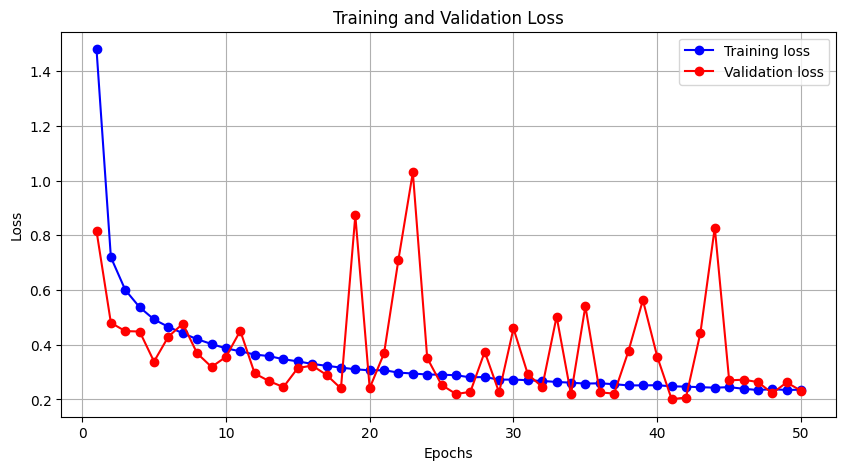

In [8]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(10, 5))
plt.plot(epochs_list, loss, 'bo-', label='Training loss')
plt.plot(epochs_list, val_loss, 'ro-', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

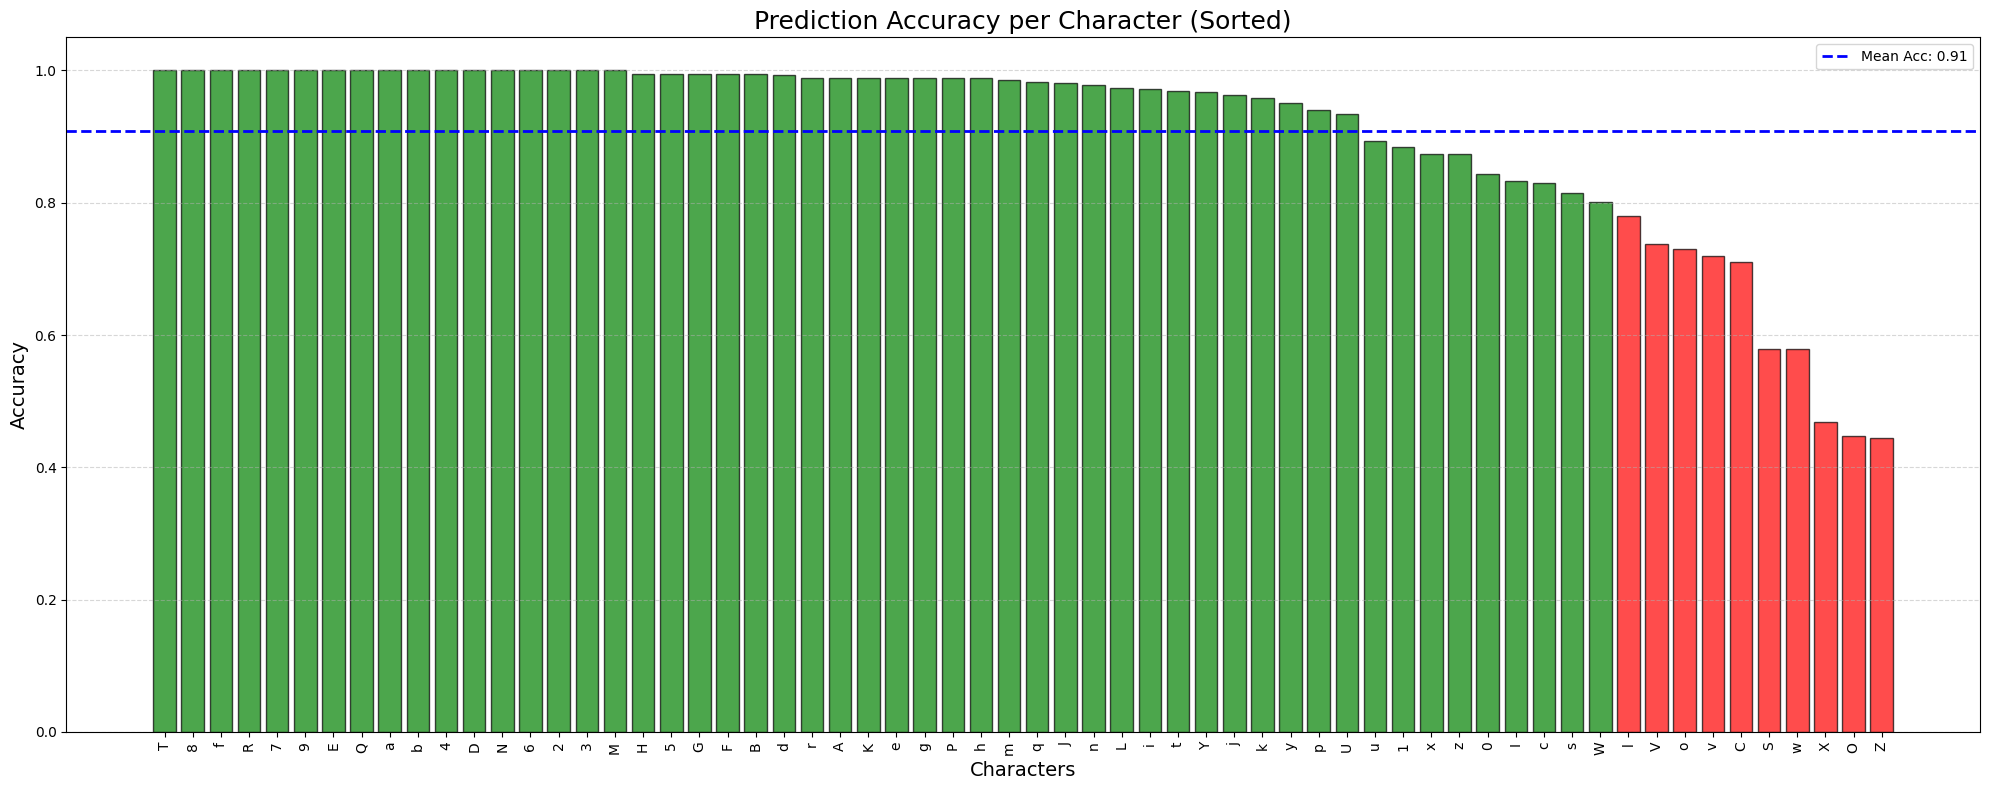

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

y_true_all = []
y_pred_all = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    pred_indices = np.argmax(preds, axis=1)

    if len(labels.shape) > 1 and labels.shape[1] > 1:
        true_indices = np.argmax(labels.numpy(), axis=1)
    else:
        true_indices = labels.numpy()

    y_true_all.extend(true_indices)
    y_pred_all.extend(pred_indices)

cm = confusion_matrix(y_true_all, y_pred_all, labels=list(label_to_char_map.keys()))
class_accuracy = cm.diagonal() / (cm.sum(axis=1) + 1e-10)
labels_text = [label_to_char_map[i] for i in range(len(label_to_char_map))]

# Sort by accuracy descending
data_pairs = list(zip(labels_text, class_accuracy))
sorted_data = sorted(data_pairs, key=lambda x: x[1], reverse=True)
sorted_labels, sorted_accuracy = zip(*sorted_data)

plt.figure(figsize=(20, 8))

colors = ['green' if acc > 0.8 else 'red' for acc in sorted_accuracy]
plt.bar(sorted_labels, sorted_accuracy, color=colors, edgecolor='black', alpha=0.7)

plt.xlabel('Characters', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Prediction Accuracy per Character (Sorted)', fontsize=18)
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.5)

global_avg = np.mean(class_accuracy)
plt.axhline(global_avg, color='blue', linestyle='--', linewidth=2, label=f'Mean Acc: {global_avg:.2f}')
plt.legend()

plt.tight_layout()
plt.show()